# 03 — RNN Family Models (Word2Vec)

> Part of a 5-notebook pipeline (run in order, each a separate kernel session — this is deliberate, see the note in the main README/first notebook):
> 1. `01_preprocessing_and_split.ipynb` — load, clean, dedupe, handle class imbalance, train/val/test split
> 2. `02_classical_ml.ipynb` — TF-IDF + Random Forest / Logistic Regression / Naive Bayes
> 3. `03_rnn_family.ipynb` — Word2Vec + SimpleRNN / GRU / LSTM (+ bidirectional variants)
> 4. `04_bert.ipynb` — BERT-base fine-tuning
> 5. `05_final_comparison.ipynb` — combined results across all 10 models
>
> **Why separate notebooks/kernels:** TensorFlow never releases GPU memory once it claims it, and PyTorch (used by BERT) initializing its own CUDA context in the same process can cause a hard, traceback-less kernel crash rather than a clean error. Keeping RNN training (TensorFlow) and BERT training (PyTorch) in different kernel processes avoids that entirely, and also caps how much of a crash costs you — a crash in notebook 4 no longer takes down anything from notebooks 1–3.
> All shared state (cleaned data, splits, trained models, results) is handed off between notebooks via files on disk, not kernel memory.

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_colwidth', 150)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1.1 Shared Result Tracking (persists across kernel restarts)

Some sections of this notebook (12, 13, 14) are expensive enough that you'll often run them in **separate kernel sessions** (e.g. restarting between the TensorFlow/RNN section and the PyTorch/BERT section to avoid the two frameworks fighting over the same GPU memory in one process — see the note in Section 14).

To make that safe, `tuning_log` (every hyperparameter run) and `final_results` (every model's final test-set metrics) are defined **once, here**, and every time a new entry is logged it's immediately saved to `tuning_log.csv` / `final_results.csv` on disk. At the top of each kernel session, this cell also **reloads whatever is already on disk**, so:
- Running only Sections 1–10 + 14 (BERT) in a fresh kernel still lets you log BERT results without a `NameError`.
- Results from an earlier kernel session (e.g. the RNN family) are still there when you get to Section 15, even though that code isn't in this session's memory.

**Run this cell every session**, right after the imports cell above, regardless of which later sections you plan to run.

In [2]:
import os
import pandas as pd

TUNING_LOG_PATH = 'tuning_log.csv'
FINAL_RESULTS_PATH = 'final_results.csv'

# Reload anything already saved from a previous kernel session, so results
# accumulate across restarts instead of resetting every time.
if os.path.exists(TUNING_LOG_PATH):
    tuning_log = pd.read_csv(TUNING_LOG_PATH).to_dict('records')
    print(f'Reloaded {len(tuning_log)} existing tuning_log rows from {TUNING_LOG_PATH}')
else:
    tuning_log = []

if os.path.exists(FINAL_RESULTS_PATH):
    final_results = pd.read_csv(FINAL_RESULTS_PATH).to_dict('records')
    print(f'Reloaded {len(final_results)} existing final_results rows from {FINAL_RESULTS_PATH}')
else:
    final_results = []


def log_run(model_name, config, val_acc, val_f1):
    """Record one hyperparameter run's validation metrics, print it, and persist immediately."""
    tuning_log.append({'model': model_name, 'config': str(config), 'val_accuracy': val_acc, 'val_f1_macro': val_f1})
    print(f"{model_name:22s} {str(config):55s} val_acc={val_acc:.4f}  val_f1_macro={val_f1:.4f}")
    pd.DataFrame(tuning_log).to_csv(TUNING_LOG_PATH, index=False)


def record_final_result(model_name, test_acc, f1_macro, f1_weighted):
    """Record one model's final test-set metrics and persist immediately."""
    # Overwrite any earlier entry for the same model name (e.g. re-running a section) rather than duplicating it.
    global final_results
    final_results = [r for r in final_results if r['model'] != model_name]
    final_results.append({'model': model_name, 'test_accuracy': test_acc, 'test_f1_macro': f1_macro, 'test_f1_weighted': f1_weighted})
    pd.DataFrame(final_results).to_csv(FINAL_RESULTS_PATH, index=False)


def best_config_row(df, model_name):
    """Given the tuning_log as a DataFrame, return the row with the best validation macro-F1 for one model."""
    sub = df[df['model'] == model_name]
    return sub.loc[sub['val_f1_macro'].idxmax()]

import hashlib
import ast

SAVED_MODELS_DIR = 'saved_models'
os.makedirs(os.path.join(SAVED_MODELS_DIR, 'classical'), exist_ok=True)
os.makedirs(os.path.join(SAVED_MODELS_DIR, 'rnn'), exist_ok=True)
os.makedirs(os.path.join(SAVED_MODELS_DIR, 'bert'), exist_ok=True)


def _config_hash(config):
    """Short, deterministic filename-safe hash of a hyperparameter config dict."""
    return hashlib.md5(str(config).encode()).hexdigest()[:10]


def classical_model_path(model_name, config):
    return os.path.join(SAVED_MODELS_DIR, 'classical', f'{model_name}__{_config_hash(config)}.joblib')


def rnn_model_path(arch_name, config):
    return os.path.join(SAVED_MODELS_DIR, 'rnn', f'{arch_name}__{_config_hash(config)}.keras')


def bert_model_path(config):
    return os.path.join(SAVED_MODELS_DIR, 'bert', _config_hash(config))


def parse_config(config_str):
    """Turn the 'config' string stored in tuning_log back into a real dict, e.g. to
    reconstruct a saved-model path from a row of tuning_log_df / best_config_row()."""
    return ast.literal_eval(config_str)

Reloaded 9 existing tuning_log rows from tuning_log.csv
Reloaded 3 existing final_results rows from final_results.csv


## 0. Reload Pipeline State from Notebook 1

Run `01_preprocessing_and_split.ipynb` first if you haven't yet — this cell just reloads what it saved, so this notebook doesn't need that kernel to still be running.

In [3]:
import joblib

train_df = pd.read_csv('train_df.csv')
val_df = pd.read_csv('val_df.csv')
test_df = pd.read_csv('test_df.csv')

label_encoder = joblib.load('label_encoder.joblib')
class_weight_dict = joblib.load('class_weight_dict.joblib')
num_classes = len(label_encoder.classes_)

y_train = label_encoder.transform(train_df['category'])
y_val = label_encoder.transform(val_df['category'])
y_test = label_encoder.transform(test_df['category'])

print('Reloaded from Notebook 1:', train_df.shape, val_df.shape, test_df.shape, ' num_classes:', num_classes)

Reloaded from Notebook 1: (46697, 12) (10006, 12) (10007, 12)  num_classes: 6


In [4]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

### 11.2 Word2Vec (self-trained on the training corpus)

In [5]:
from gensim.models import Word2Vec

EMBED_DIM = 200

tokenized_train = train_df['clean_summary'].apply(str.split).tolist()

w2v_model = Word2Vec(
    sentences=tokenized_train,
    vector_size=EMBED_DIM,
    window=5,
    min_count=2,
    workers=4,
    sg=1,          # skip-gram; generally stronger than CBOW for smaller/domain-specific corpora
    epochs=10,
    seed=RANDOM_STATE,
)

print('Word2Vec vocabulary size:', len(w2v_model.wv))
print('Most similar to "neural":', w2v_model.wv.most_similar('neural', topn=5))

Word2Vec vocabulary size: 41507
Most similar to "neural": [('network', 0.6635556817054749), ('grnn', 0.6453627943992615), ('ffnns', 0.6298272013664246), ('slfn', 0.6289162039756775), ('elman', 0.6253756284713745)]


**Note:** we train Word2Vec on the training split's vocabulary. This means any word appearing only in val/test and not in train will have no embedding — this is expected and standard practice (it mirrors how the model would behave on genuinely unseen words in production); the Keras Tokenizer/embedding matrix step below handles out-of-vocabulary words by mapping them to a zero vector.

## 13. Deep Learning Models — RNN Family

Six architectures required: **SimpleRNN, GRU, LSTM**, and their **Bidirectional** counterparts. All share the same data prep (Keras tokenizer + padded sequences + a Word2Vec-initialized embedding matrix) and the same training/tuning loop, parameterized by architecture.

**GPU notes for the RTX 3060 (12GB):** this whole family is lightweight — batch size 128, embedding dim 200, and up to 256 hidden units per direction all fit with room to spare. `tf.data`/Keras will use the GPU automatically if TensorFlow detects it; the explicit device check below just confirms that.

In [6]:
import tensorflow as tf
print('GPUs visible to TensorFlow:', tf.config.list_physical_devices('GPU'))

# Optional but recommended on a 12GB card: let TF grow GPU memory allocation as needed
# instead of grabbing all 12GB up front (avoids OOM conflicts with anything else using the GPU).
gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

I0000 00:00:1787484500.503342   16301 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1787484500.533758   16301 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1787484501.845808   16301 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPUs visible to TensorFlow: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [7]:
details = tf.config.experimental.get_device_details(tf.config.list_physical_devices('GPU')[0])
print(details)

{'compute_capability': (8, 6), 'device_name': 'NVIDIA GeForce RTX 3060'}


In [8]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_VOCAB = 30000
MAX_LEN = 256  # covers the large majority of cleaned abstracts (see Section 5 word-count distribution)

keras_tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token='<OOV>')
keras_tokenizer.fit_on_texts(train_df['clean_summary'])

X_train_seq = pad_sequences(keras_tokenizer.texts_to_sequences(train_df['clean_summary']), maxlen=MAX_LEN, padding='post', truncating='post')
X_val_seq = pad_sequences(keras_tokenizer.texts_to_sequences(val_df['clean_summary']), maxlen=MAX_LEN, padding='post', truncating='post')
X_test_seq = pad_sequences(keras_tokenizer.texts_to_sequences(test_df['clean_summary']), maxlen=MAX_LEN, padding='post', truncating='post')

vocab_size = min(MAX_VOCAB, len(keras_tokenizer.word_index) + 1)
print('Effective vocab size:', vocab_size)
print('Sequence shapes -> train:', X_train_seq.shape, ' val:', X_val_seq.shape, ' test:', X_test_seq.shape)

Effective vocab size: 30000
Sequence shapes -> train: (46697, 256)  val: (10006, 256)  test: (10007, 256)


In [9]:
# Build an embedding matrix from the Word2Vec model trained in Section 11.2.
# Words in the Keras vocab but not in the Word2Vec vocab (rare/OOV words) get a zero vector.
embedding_matrix = np.zeros((vocab_size, EMBED_DIM))
hits, misses = 0, 0
for word, idx in keras_tokenizer.word_index.items():
    if idx >= vocab_size:
        continue
    if word in w2v_model.wv:
        embedding_matrix[idx] = w2v_model.wv[word]
        hits += 1
    else:
        misses += 1

print(f'Embedding matrix: {hits} words matched to Word2Vec, {misses} words unmatched (left as zero vectors)')

Embedding matrix: 29998 words matched to Word2Vec, 1 words unmatched (left as zero vectors)


In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, GRU, LSTM, Bidirectional, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

def build_rnn_model(cell_type, units, bidirectional, dropout, learning_rate):
    cell_cls = {'SimpleRNN': SimpleRNN, 'GRU': GRU, 'LSTM': LSTM}[cell_type]
    recurrent_layer = cell_cls(units, dropout=dropout)
    if bidirectional:
        recurrent_layer = Bidirectional(recurrent_layer)

    model = Sequential([
        Embedding(input_dim=vocab_size, output_dim=EMBED_DIM, weights=[embedding_matrix],
                  trainable=True, mask_zero=True),
        recurrent_layer,
        Dropout(dropout),
        Dense(64, activation='relu'),
        Dense(num_classes, activation='softmax'),
    ])
    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

**Architectures and hyperparameter grid.** Each of the 6 architectures gets 3 configurations (units / dropout / learning rate), trained with early stopping on validation loss (patience=2) so weaker configs don't waste GPU time. All results are logged to `tuning_log` (same table as the classical models, for one unified appendix table in the report).

In [11]:
rnn_architectures = [
    ('SimpleRNN', False),
    ('GRU', False),
    ('LSTM', False),
    ('SimpleRNN', True),
    ('GRU', True),
    ('LSTM', True),
]

rnn_hparam_configs = [
    {'units': 64,  'dropout': 0.2, 'learning_rate': 1e-3},
    {'units': 128, 'dropout': 0.3, 'learning_rate': 1e-3},
    {'units': 128, 'dropout': 0.3, 'learning_rate': 5e-4},
]

BATCH_SIZE = 128
EPOCHS = 15

rnn_trained_models = {}

for cell_type, bidirectional in rnn_architectures:
    arch_name = ('Bi' if bidirectional else '') + cell_type
    for cfg in rnn_hparam_configs:
        path = rnn_model_path(arch_name, cfg)
        if os.path.exists(path):
            print(f'Already trained -- loading {path}')
            model = tf.keras.models.load_model(path)
        else:
            tf.random.set_seed(RANDOM_STATE)
            model = build_rnn_model(cell_type, bidirectional=bidirectional, **cfg)
            es = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

            model.fit(
                X_train_seq, y_train,
                validation_data=(X_val_seq, y_val),
                epochs=EPOCHS,
                batch_size=BATCH_SIZE,
                class_weight=class_weight_dict,
                callbacks=[es],
                verbose=0,
            )
            model.save(path)
            print(f'Trained and saved to {path}')

        val_pred = np.argmax(model.predict(X_val_seq, batch_size=BATCH_SIZE, verbose=0), axis=1)
        val_acc = accuracy_score(y_val, val_pred)
        val_f1 = f1_score(y_val, val_pred, average='macro')
        log_run(arch_name, cfg, val_acc, val_f1)
        rnn_trained_models[(arch_name, str(cfg))] = model

Already trained -- loading saved_models/rnn/SimpleRNN__c4de2d796c.keras


I0000 00:00:1787484505.590275   16301 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9707 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:01:00.0, compute capability: 8.6
I0000 00:00:1787484506.424909   16842 service.cc:153] XLA service 0x7b39080401a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1787484506.424948   16842 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3060, Compute Capability 8.6 (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.20.0)
I0000 00:00:1787484506.438064   16842 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1787484506.460045   16842 cuda_dnn.cc:461] Loaded cuDNN version 92000
I0000 00:00:1787484506.628074   16842 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not co

SimpleRNN              {'units': 64, 'dropout': 0.2, 'learning_rate': 0.001}   val_acc=0.5803  val_f1_macro=0.5542


I0000 00:00:1787484510.811202   16841 dot_merger.cc:481] Merging Dots in computation: sequential_1_simple_rnn_1_while_body_3328_grad_3565_const_0__.23.clone.clone.clone.clone.clone.clone.clone.clone
I0000 00:00:1787484510.811291   16841 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_4271__.27
I0000 00:00:1787484510.845745   16841 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1787484511.094121   17093 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_24', 12 bytes spill stores, 12 bytes spill loads

I0000 00:00:1787484511.116299   16841 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good r

Trained and saved to saved_models/rnn/SimpleRNN__f38a7ac942.keras
SimpleRNN              {'units': 128, 'dropout': 0.3, 'learning_rate': 0.001}  val_acc=0.5587  val_f1_macro=0.4986


...

Trained and saved to saved_models/rnn/BiSimpleRNN__c4de2d796c.keras
BiSimpleRNN            {'units': 64, 'dropout': 0.2, 'learning_rate': 0.001}   val_acc=0.6828  val_f1_macro=0.6745


I0000 00:00:1787485638.144228   16835 dot_merger.cc:481] Merging Dots in computation: sequential_9_1_bidirectional_1_1_backward_simple_rnn_3_1_while_body_140079_grad_140684_const_0__.22.clone.clone.clone.clone.clone.clone.clone.clone
I0000 00:00:1787485638.144330   16835 dot_merger.cc:481] Merging Dots in computation: sequential_9_1_bidirectional_1_1_forward_simple_rnn_3_1_while_body_139906_grad_140334_const_0__.35.clone.clone.clone.clone.clone.clone.clone.clone
I0000 00:00:1787485638.144378   16835 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_141519__.39
I0000 00:00:1787485638.271709   16835 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1787485638.531631   25316 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory i

Trained and saved to saved_models/rnn/BiSimpleRNN__f38a7ac942.keras
BiSimpleRNN            {'units': 128, 'dropout': 0.3, 'learning_rate': 0.001}  val_acc=0.6693  val_f1_macro=0.6467


I0000 00:00:1787485834.065858   16839 dot_merger.cc:481] Merging Dots in computation: sequential_10_1_bidirectional_2_1_backward_simple_rnn_4_1_while_body_152283_grad_152888_const_0__.22.clone.clone.clone.clone.clone.clone.clone.clone
I0000 00:00:1787485834.065958   16839 dot_merger.cc:481] Merging Dots in computation: sequential_10_1_bidirectional_2_1_forward_simple_rnn_4_1_while_body_152110_grad_152538_const_0__.35.clone.clone.clone.clone.clone.clone.clone.clone
I0000 00:00:1787485834.066007   16839 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_153723__.39
I0000 00:00:1787485892.529295   16835 dot_merger.cc:481] Merging Dots in computation: sequential_10_1_bidirectional_2_1_backward_simple_rnn_4_1_while_body_152283_grad_152888_const_0__.22.clone.clone.clone.clone.clone.clone.clone.clone
I0000 00:00:1787485892.529393   16835 dot_merger.cc:481] Merging Dots in computation: sequential_10_1_bidirectional_2_1_forward_simple_rnn_4_1_while_body_152110_grad_152

Trained and saved to saved_models/rnn/BiSimpleRNN__51c4d3c44c.keras
BiSimpleRNN            {'units': 128, 'dropout': 0.3, 'learning_rate': 0.0005} val_acc=0.7156  val_f1_macro=0.7101
Trained and saved to saved_models/rnn/BiGRU__c4de2d796c.keras
BiGRU                  {'units': 64, 'dropout': 0.2, 'learning_rate': 0.001}   val_acc=0.7540  val_f1_macro=0.7477
Trained and saved to saved_models/rnn/BiGRU__f38a7ac942.keras
BiGRU                  {'units': 128, 'dropout': 0.3, 'learning_rate': 0.001}  val_acc=0.7549  val_f1_macro=0.7462
Trained and saved to saved_models/rnn/BiGRU__51c4d3c44c.keras
BiGRU                  {'units': 128, 'dropout': 0.3, 'learning_rate': 0.0005} val_acc=0.7605  val_f1_macro=0.7544
Trained and saved to saved_models/rnn/BiLSTM__c4de2d796c.keras
BiLSTM                 {'units': 64, 'dropout': 0.2, 'learning_rate': 0.001}   val_acc=0.7518  val_f1_macro=0.7472
Trained and saved to saved_models/rnn/BiLSTM__f38a7ac942.keras
BiLSTM                 {'units': 128, 'dropou

In [12]:
tuning_log_df = pd.DataFrame(tuning_log)  # refresh with the RNN runs included
tuning_log_df[tuning_log_df['model'].str.contains('RNN|GRU|LSTM')]

,model,config,val_accuracy,val_f1_macro
9,SimpleRNN,"{'units': 64, 'dropout': 0.2, 'learning_rate': 0.001}",0.580252,0.554154
10,SimpleRNN,"{'units': 128, 'dropout': 0.3, 'learning_rate': 0.001}",0.558665,0.498624
11,SimpleRNN,"{'units': 128, 'dropout': 0.3, 'learning_rate': 0.0005}",0.527883,0.476734
12,GRU,"{'units': 64, 'dropout': 0.2, 'learning_rate': 0.001}",0.757146,0.752101
13,GRU,"{'units': 128, 'dropout': 0.3, 'learning_rate': 0.001}",0.761443,0.756790
14,GRU,"{'units': 128, 'dropout': 0.3, 'learning_rate': 0.0005}",0.767639,0.768031
15,LSTM,"{'units': 64, 'dropout': 0.2, 'learning_rate': 0.001}",0.749550,0.748244
16,LSTM,"{'units': 128, 'dropout': 0.3, 'learning_rate': 0.001}",0.752349,0.748777
17,LSTM,"{'units': 128, 'dropout': 0.3, 'learning_rate': 0.0005}",0.761343,0.761344
18,BiSimpleRNN,"{'units': 64, 'dropout': 0.2, 'learning_rate': 0.001}",0.682790,0.674525


Best config for SimpleRNN: {'units': 64, 'dropout': 0.2, 'learning_rate': 0.001}  (val_f1_macro=0.5542)


I0000 00:00:1787486883.948410   16842 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1787486884.239255   32838 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_10', 12 bytes spill stores, 12 bytes spill loads

I0000 00:00:1787486884.320608   16842 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1787486884.593711   32849 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_1_10', 12 bytes spill stores, 12 bytes spill loads



=== SimpleRNN (test set) ===
Accuracy: 0.5769   Macro-F1: 0.5527   Weighted-F1: 0.5498
                                                        precision    recall  f1-score   support

                               Artificial Intelligence       0.54      0.41      0.46      1800
Computation and Language (Natural Language Processing)       0.61      0.79      0.69      1800
               Computer Vision and Pattern Recognition       0.78      0.68      0.73      1800
                                      Machine Learning       0.39      0.15      0.21      1800
                         Machine Learning (Statistics)       0.52      0.81      0.64      1800
                     Neural and Evolutionary Computing       0.53      0.67      0.59      1007

                                              accuracy                           0.58     10007
                                             macro avg       0.56      0.58      0.55     10007
                                          weigh

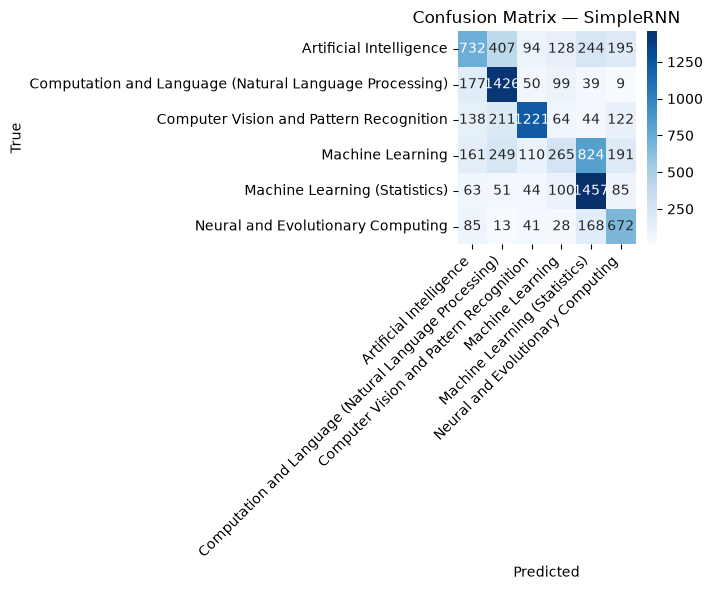

Best config for GRU: {'units': 128, 'dropout': 0.3, 'learning_rate': 0.0005}  (val_f1_macro=0.7680)
=== GRU (test set) ===
Accuracy: 0.7600   Macro-F1: 0.7599   Weighted-F1: 0.7558
                                                        precision    recall  f1-score   support

                               Artificial Intelligence       0.73      0.71      0.72      1800
Computation and Language (Natural Language Processing)       0.85      0.81      0.83      1800
               Computer Vision and Pattern Recognition       0.83      0.93      0.88      1800
                                      Machine Learning       0.62      0.52      0.57      1800
                         Machine Learning (Statistics)       0.72      0.78      0.75      1800
                     Neural and Evolutionary Computing       0.77      0.85      0.81      1007

                                              accuracy                           0.76     10007
                                             macr

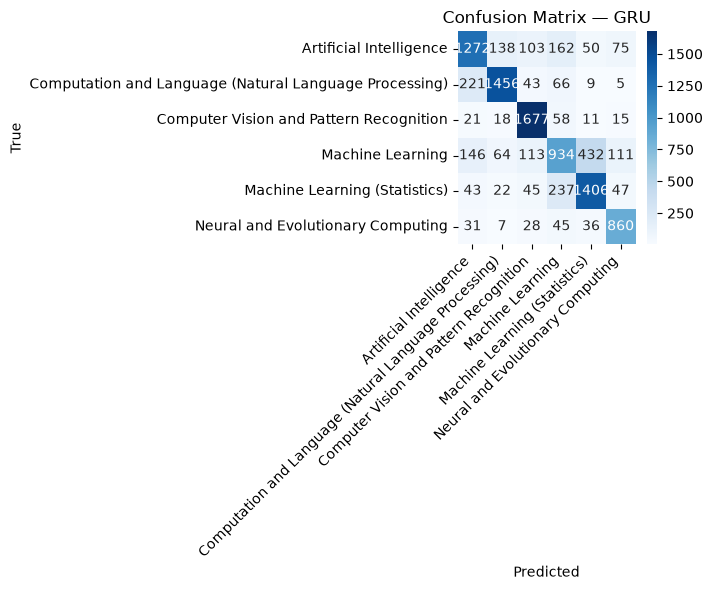

Best config for LSTM: {'units': 128, 'dropout': 0.3, 'learning_rate': 0.0005}  (val_f1_macro=0.7613)
=== LSTM (test set) ===
Accuracy: 0.7514   Macro-F1: 0.7512   Weighted-F1: 0.7467
                                                        precision    recall  f1-score   support

                               Artificial Intelligence       0.74      0.64      0.69      1800
Computation and Language (Natural Language Processing)       0.83      0.84      0.83      1800
               Computer Vision and Pattern Recognition       0.83      0.93      0.88      1800
                                      Machine Learning       0.60      0.52      0.56      1800
                         Machine Learning (Statistics)       0.71      0.78      0.74      1800
                     Neural and Evolutionary Computing       0.78      0.84      0.81      1007

                                              accuracy                           0.75     10007
                                             ma

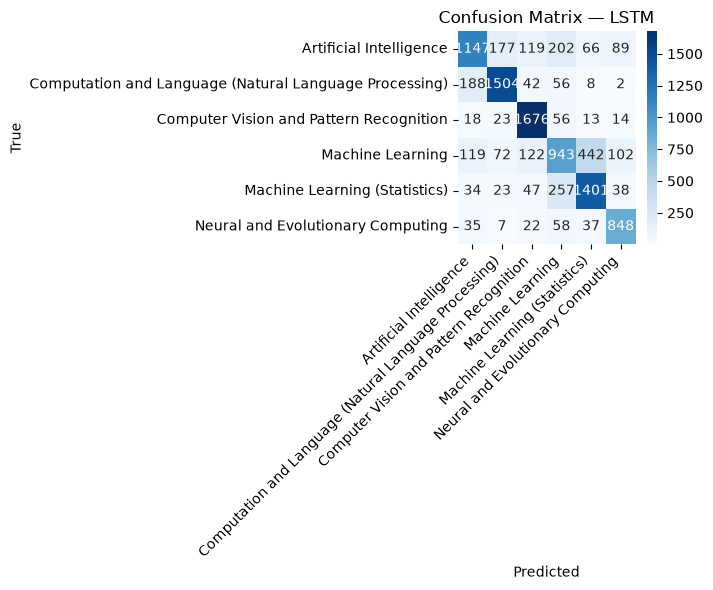

Best config for BiSimpleRNN: {'units': 128, 'dropout': 0.3, 'learning_rate': 0.0005}  (val_f1_macro=0.7101)
=== BiSimpleRNN (test set) ===
Accuracy: 0.7182   Macro-F1: 0.7140   Weighted-F1: 0.7101
                                                        precision    recall  f1-score   support

                               Artificial Intelligence       0.68      0.70      0.69      1800
Computation and Language (Natural Language Processing)       0.85      0.77      0.81      1800
               Computer Vision and Pattern Recognition       0.80      0.89      0.85      1800
                                      Machine Learning       0.60      0.39      0.47      1800
                         Machine Learning (Statistics)       0.62      0.83      0.71      1800
                     Neural and Evolutionary Computing       0.78      0.75      0.76      1007

                                              accuracy                           0.72     10007
                                 

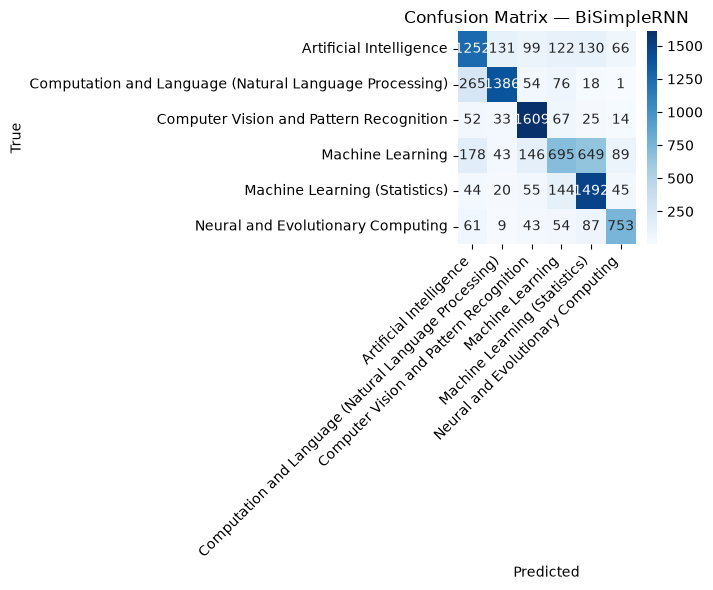

Best config for BiGRU: {'units': 128, 'dropout': 0.3, 'learning_rate': 0.0005}  (val_f1_macro=0.7544)
=== BiGRU (test set) ===
Accuracy: 0.7586   Macro-F1: 0.7525   Weighted-F1: 0.7485
                                                        precision    recall  f1-score   support

                               Artificial Intelligence       0.71      0.74      0.72      1800
Computation and Language (Natural Language Processing)       0.83      0.84      0.83      1800
               Computer Vision and Pattern Recognition       0.84      0.93      0.88      1800
                                      Machine Learning       0.70      0.42      0.52      1800
                         Machine Learning (Statistics)       0.70      0.81      0.75      1800
                     Neural and Evolutionary Computing       0.74      0.88      0.80      1007

                                              accuracy                           0.76     10007
                                             

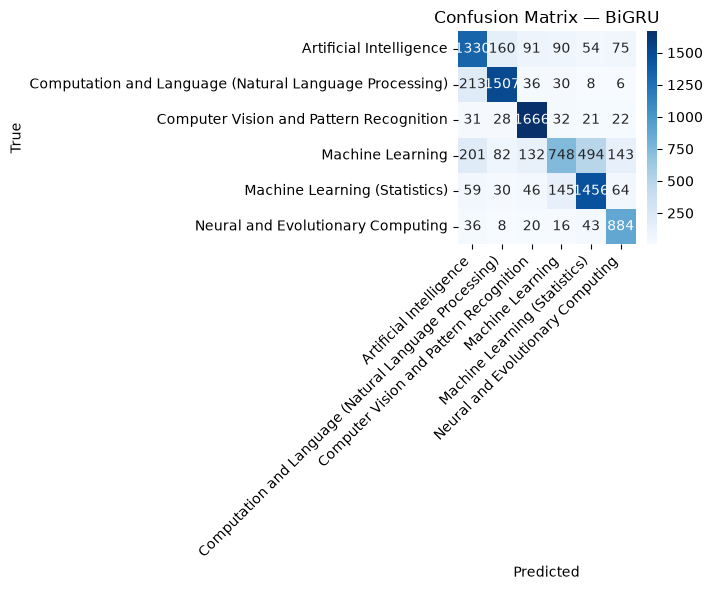

Best config for BiLSTM: {'units': 128, 'dropout': 0.3, 'learning_rate': 0.0005}  (val_f1_macro=0.7542)
=== BiLSTM (test set) ===
Accuracy: 0.7529   Macro-F1: 0.7472   Weighted-F1: 0.7442
                                                        precision    recall  f1-score   support

                               Artificial Intelligence       0.74      0.69      0.71      1800
Computation and Language (Natural Language Processing)       0.84      0.82      0.83      1800
               Computer Vision and Pattern Recognition       0.83      0.93      0.87      1800
                                      Machine Learning       0.66      0.44      0.52      1800
                         Machine Learning (Statistics)       0.69      0.83      0.75      1800
                     Neural and Evolutionary Computing       0.72      0.86      0.79      1007

                                              accuracy                           0.75     10007
                                           

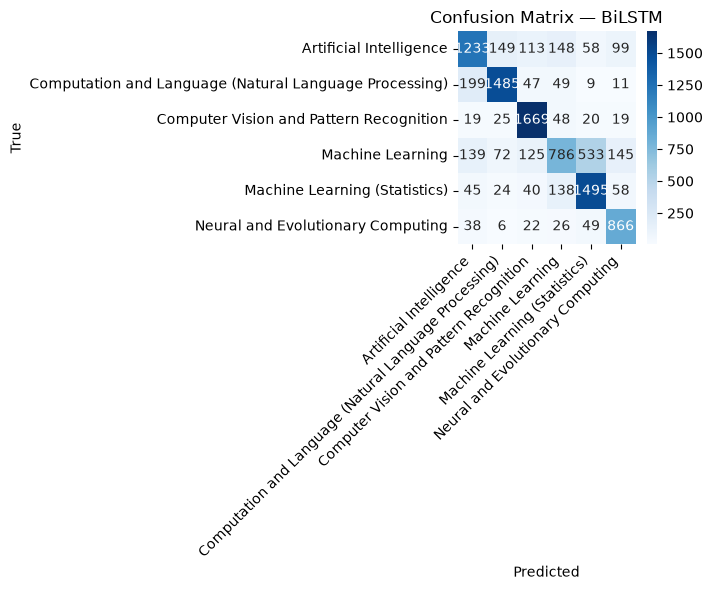

In [13]:
for cell_type, bidirectional in rnn_architectures:
    arch_name = ('Bi' if bidirectional else '') + cell_type
    best_row = best_config_row(tuning_log_df, arch_name)
    best_cfg = parse_config(best_row['config'])
    path = rnn_model_path(arch_name, best_cfg)
    best_model = rnn_trained_models.get((arch_name, best_row['config'])) or tf.keras.models.load_model(path)
    print(f'Best config for {arch_name}: {best_row["config"]}  (val_f1_macro={best_row["val_f1_macro"]:.4f})')

    val_or_test_pred = np.argmax(best_model.predict(X_test_seq, batch_size=BATCH_SIZE, verbose=0), axis=1)
    acc = accuracy_score(y_test, val_or_test_pred)
    f1_macro = f1_score(y_test, val_or_test_pred, average='macro')
    f1_weighted = f1_score(y_test, val_or_test_pred, average='weighted')
    cm = confusion_matrix(y_test, val_or_test_pred)
    report = classification_report(y_test, val_or_test_pred, target_names=label_encoder.classes_)

    print(f'=== {arch_name} (test set) ===')
    print(f'Accuracy: {acc:.4f}   Macro-F1: {f1_macro:.4f}   Weighted-F1: {f1_weighted:.4f}')
    print(report)

    plt.figure(figsize=(7,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
    plt.title(f'Confusion Matrix — {arch_name}')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    record_final_result(arch_name, acc, f1_macro, f1_weighted)